In [28]:
from google.colab import files

# Jalankan kode ini untuk memunculkan tombol "Choose Files"
uploaded = files.upload()

Saving aerilly.jpg to aerilly (2).jpg


In [ ]:
# TRANSLASI CITRA

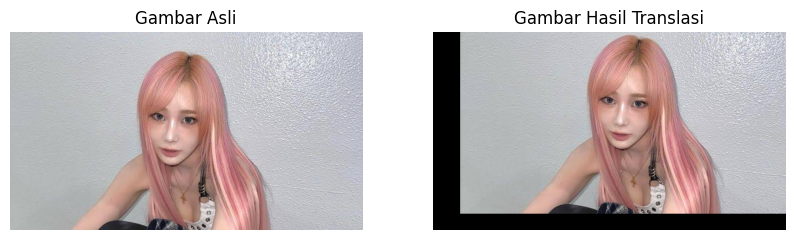

In [29]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def translasi(image, shift_x, shift_y):
    # Menggeser gambar secara vertikal dan horizontal
    shifted_img = np.roll(image, shift_y, axis=0)
    shifted_img = np.roll(shifted_img, shift_x, axis=1)

    # Mengisi area kosong dengan piksel hitam (0)
    if shift_y > 0:
        shifted_img[:shift_y, :, :] = 0  # Geser ke bawah (bagian atas hitam)
    elif shift_y < 0:
        shifted_img[shift_y:, :, :] = 0  # Geser ke atas (bagian bawah hitam)

    if shift_x > 0:
        shifted_img[:, :shift_x, :] = 0  # Geser ke kanan (bagian kiri hitam)
    elif shift_x < 0:
        shifted_img[:, shift_x:, :] = 0  # Geser ke kiri (bagian kanan hitam)

    return shifted_img

try:
    # Membaca file gambar yang baru saja Anda upload (aerilly.jpg)
    image = img.imread("aerilly.jpg")

    # Melakukan translasi (contoh geser kanan 50 piksel, geser atas 30 piksel)
    img_result = translasi(image, shift_x=50, shift_y=-30)

    # Menampilkan visualisasi
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.title("Gambar Asli")
    plt.imshow(image)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("Gambar Hasil Translasi")
    plt.imshow(img_result)
    plt.axis('off')

    plt.show()
except Exception as e:
    print("Terjadi kesalahan saat memproses gambar:", e)

In [ ]:
# MIRRORING

/tmp/ipykernel_3871/4249584708.py:6: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread(path)


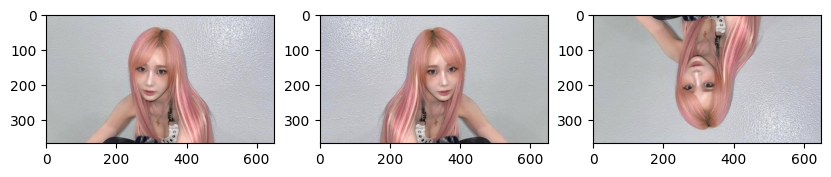

In [30]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

path = 'aerilly.jpg'
image = img.imread(path)

height, width = image.shape[:2]
horizontal = np.zeros_like(image)
vertical = np.zeros_like(image)

for y in range(height):
    for x in range(width):
        horizontal[y, x] = image[y, width - 1 - x]

for y in range(height):
    for x in range(width):
        vertical [y,x] = image [height - 1-y,x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)

plt.subplot(1, 3, 2)
plt.imshow(horizontal)

plt.subplot(1, 3, 3)
plt.imshow(vertical)


plt.show()

In [ ]:
# ROTASI CITRA

/tmp/ipykernel_3871/3495605220.py:28: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('aerilly.jpg')


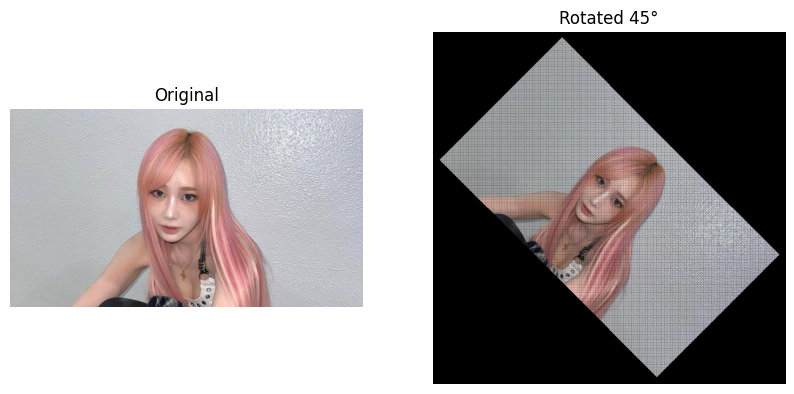

In [35]:
import imageio as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImage(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    max_dim = int(np.sqrt(height**2 + width**2))
    output_image = np.zeros((max_dim, max_dim, 3), dtype=image.dtype)

    centerY, centerX = max_dim // 2, max_dim // 2

    for y in range(-height // 2, height // 2):
        for x in range(-width // 2, width // 2):
            # Menggunakan perkalian (*) yang benar
            newX = int(cos_deg * x - sin_deg * y) + centerX
            newY = int(sin_deg * x + cos_deg * y) + centerY
            # Memperbaiki logika perbandingan
            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                output_image[newY, newX] = image[y + height // 2, x + width // 2]

    return output_image

try:
    # Membaca file gambar yang diunggah di Colab
    image = img.imread('aerilly.jpg')
    rotated_image = rotateImage(image, 45)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.title("Original")
    plt.imshow(image)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("Rotated 45°")
    plt.imshow(rotated_image)
    plt.axis('off')

    plt.show()
except Exception as e:
    print("Terjadi kesalahan saat memproses gambar:", e)

In [ ]:
# ZOOMING

/tmp/ipykernel_3871/2130779892.py:31: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('aerilly.jpg')


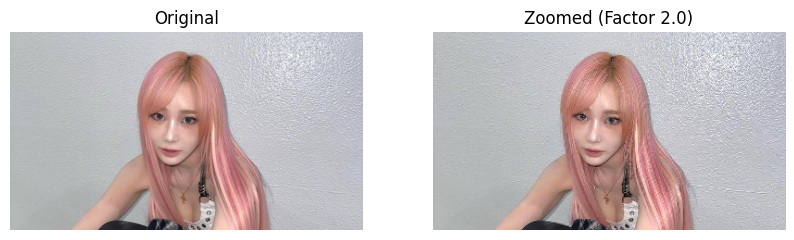

In [36]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

def zoomPlus(image, factor):
    # Menambahkan indentasi yang benar di dalam fungsi
    height, width = image.shape[:2]

    new_height = int(height / factor)
    new_width = int(width / factor)

    # Memperbaiki nama variabel new_width (tanpa spasi)
    imgZoom = np.zeros((new_height, new_width, 3), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):
            # Memperbaiki operator perkalian (*)
            ori_y = int(y * factor)
            ori_x = int(x * factor)

            # Memperbaiki operator pengurangan (-)
            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom

try:
    # Menggunakan gambar aerilly.jpg yang sudah ada di Colab
    image = img.imread('aerilly.jpg')
    skala = 2.0

    imgZoom = zoomPlus(image, skala)

    # Menampilkan hasil visualisasi
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.title("Original")
    plt.imshow(image)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("Zoomed (Factor 2.0)")
    plt.imshow(imgZoom)
    plt.axis('off')

    plt.show()
except Exception as e:
    print("Terjadi kesalahan saat memproses gambar:", e)